# Projet 01 — Profils de fonctionnement des bornes fontaines

**Apprentissage non supervisé — K-Means & ACP**

**Mission :** Construire une typologie descriptive des bornes et distinguer intensité de service, disponibilité et attente.

**Unité étudiée :** une borne fontaine observée pendant une semaine.

---

In [1]:
# ============================================================
# Imports et configuration globale
# ============================================================
import glob, os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42
SEEDS = [42, 0, 1, 7, 123]

print('Configuration OK')

Configuration OK


---
# Phase 1 — Diagnostic et préparation des données
---

## Question 01 — Définir les observations

**Que représente une ligne dans le fichier et quelle unité comparerons-nous ?**

Chaque ligne du fichier `mesures_brutes.csv` représente **une borne fontaine observée pendant une semaine**.

On distingue :
- **Clés et contexte** (à exclure des distances) : `id_observation`, `commune`, `date_releve`
- **Variables descriptives candidates** (pour le clustering) : `volume_m3`, `passages`, `attente_min`, `ouverture_h`, `pression_bar`, `interruption_h`, `stockage_m3`

L'unité d'analyse finale est la borne-semaine. Les clés servent à identifier et interpréter, pas à calculer des distances.

In [2]:
# Q01 — Localisation et aperçu du fichier
data_files = glob.glob('../**/01_bornes_fontaines/donnees/mesures_brutes.csv', recursive=True)
if not data_files:
    data_files = glob.glob('**/01_bornes_fontaines/donnees/mesures_brutes.csv', recursive=True)
if not data_files:
    data_files = glob.glob('C:/Users/Michel ONDO/Documents/Project AI/**/mesures_brutes.csv', recursive=True)
print('Fichier trouvé :', data_files)
DATA_PATH = data_files[0]

Fichier trouvé : ['..\\projet apprentissage supervisé etudiant\\projet etudiant\\01_bornes_fontaines\\donnees\\mesures_brutes.csv']


## Question 02 — Importer sans perdre d'information

In [3]:
# Q02 — Chargement brut en texte intégral
df_brut = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig',
                       dtype=str, keep_default_na=False)

# Copie intacte pour comparaison ultérieure
df_raw_backup = df_brut.copy()

print(f'Dimensions : {df_brut.shape[0]} lignes × {df_brut.shape[1]} colonnes')
print(f'\nColonnes : {list(df_brut.columns)}')
print()
df_brut.head(5)

Dimensions : 984 lignes × 10 colonnes

Colonnes : ['id_observation', 'commune', 'date_releve', 'volume_m3', 'passages', 'attente_min', 'ouverture_h', 'pression_bar', 'interruption_h', 'stockage_m3']



,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
0,P01_00396,Zone_B,2025-05-16,103.966,1125,5.516,77.472,3.654,2.015,72.833
1,P01_00255,Zone_A,2025-01-17,"113,987",626,2.795,69.548,3.334,3.884,69.4
2,P01_00889,Zone_B,2026-02-18,44.792,907,18.838,43.143,1.398,14.781,16.906
3,P01_00099,Zone_C,2026-04-18,40123,1361,26.297,NA,1.139,18.985,14.773
4,P01_00289,Zone_B,2025-07-07,83.295,636,4.963,73.317,3.206,0.61,50.597


In [4]:
# Q02 — Types lus (tout est object/str)
print(df_brut.dtypes)
print(f'\nNombre de lignes : {len(df_brut)}')
print(f'Nombre de colonnes : {len(df_brut.columns)}')

id_observation    str
commune           str
date_releve       str
volume_m3         str
passages          str
attente_min       str
ouverture_h       str
pression_bar      str
interruption_h    str
stockage_m3       str
dtype: object

Nombre de lignes : 984
Nombre de colonnes : 10


**Commentaire Q02 :** Toutes les cellules ont été lues comme du texte (`dtype=str`) avec `keep_default_na=False` pour ne pas transformer automatiquement les valeurs manquantes. Le séparateur est `;` et l'encodage `utf-8-sig`. On conserve `df_raw_backup` intacte.

## Question 03 — Auditer les clés et les répétitions

In [5]:
# Q03 — Doublons stricts (toutes colonnes identiques)
nb_doublons_stricts = df_brut.duplicated().sum()
print(f'Doublons stricts (toutes colonnes) : {nb_doublons_stricts}')

# Clés absentes ou vides
missing_vals = ['', 'NA', '?', 'non renseigne', 'NaN', 'nan']
cles_absentes = df_brut['id_observation'].apply(lambda x: x.strip() in missing_vals).sum()
print(f'Clés id_observation absentes ou vides : {cles_absentes}')

# Clés dupliquées
id_counts = df_brut['id_observation'].value_counts()
ids_dupliques = id_counts[id_counts > 1]
print(f'\nClés id_observation répétées : {len(ids_dupliques)}')

if len(ids_dupliques) > 0:
    print('\nExemples de clés répétées :')
    for dup_id in ids_dupliques.index[:5]:
        subset = df_brut[df_brut['id_observation'] == dup_id]
        print(f'\n--- {dup_id} ({len(subset)} occurrences) ---')
        display(subset)

Doublons stricts (toutes colonnes) : 19
Clés id_observation absentes ou vides : 2

Clés id_observation répétées : 23

Exemples de clés répétées :

--- P01_00698 (3 occurrences) ---


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
44,P01_00698,Zone_A,2025-07-09,60.915,1353,25.773,56.445,0.94,16.42,15.803
283,P01_00698,Zone_A,2025-07-09,60.915,1353,25.773,56.445,0.94,16.42,15.803
693,P01_00698,Zone_A,2025-07-09,a_verifier,1353,25.773,56.445,0.94,16.42,15.803



--- P01_00194 (3 occurrences) ---


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
238,P01_00194,Zone_D,2025-12-08,178.487,1836,17.817,92.97,1.998,6.475,42.972
309,P01_00194,Zone_D,2025-12-08,a_verifier,1836,17.817,92.97,1.998,6.475,42.972
670,P01_00194,Zone_D,2025-12-08,178.487,1836,17.817,92.97,1.998,6.475,42.972



--- P01_00255 (2 occurrences) ---


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
1,P01_00255,Zone_A,2025-01-17,"113,987",626,2.795,69.548,3.334,3.884,69.4
198,P01_00255,Zone_A,2025-01-17,"113,987",626,2.795,69.548,3.334,3.884,69.4



--- P01_00484 (2 occurrences) ---


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
91,P01_00484,Zone_A,2025-01-06,a_verifier,442,0.0,77.227,3.029,2.698,61.507
627,P01_00484,Zone_A,2025-01-06,68.126,442,0.0,77.227,3.029,2.698,61.507



--- P01_00734 (2 occurrences) ---


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
94,P01_00734,Zone_C,2025-12-21,125.719,680,11.58,73.668,3.441,0.0,non renseigne
359,P01_00734,Zone_C,2025-12-21,125.719,680,11.58,73.668,3.441,0.0,non renseigne


In [6]:
# Q03 — Identifier doublons stricts vs clés contradictoires
if len(ids_dupliques) > 0:
    contradictoires = []
    vrais_doublons = []
    for dup_id in ids_dupliques.index:
        subset = df_brut[df_brut['id_observation'] == dup_id]
        if subset.duplicated().any():
            vrais_doublons.append(dup_id)
        else:
            contradictoires.append(dup_id)
    print(f'Vrais doublons (lignes identiques) : {len(vrais_doublons)}')
    print(f'Clés contradictoires (même ID, contenu différent) : {len(contradictoires)}')
    if contradictoires:
        print('\nExemples contradictoires :')
        for c in contradictoires[:3]:
            display(df_brut[df_brut['id_observation'] == c])

Vrais doublons (lignes identiques) : 19
Clés contradictoires (même ID, contenu différent) : 4

Exemples contradictoires :


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
91,P01_00484,Zone_A,2025-01-06,a_verifier,442,0.0,77.227,3.029,2.698,61.507
627,P01_00484,Zone_A,2025-01-06,68.126,442,0.0,77.227,3.029,2.698,61.507


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
196,P01_00410,Zone_A,2025-08-06,98.292 m3,585,4.985,69.936,3.214,2.728,60.005
345,P01_00410,Zone_A,2025-08-06,a_verifier,585,4.985,69.936,3.214,2.728,60.005


,id_observation,commune,date_releve,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
337,P01_00574,Zone_A,2026-03-08,a_verifier,2116,12.288,88.531,1.023 bar,7.059,18.264
492,P01_00574,Zone_A,2026-03-08,174.664,2116,12.288,88.531,1.023 bar,7.059,18.264


**Commentaire Q03 :** On distingue les vrais doublons (lignes strictement identiques, à dé-dupliquer) des clés contradictoires (même identifiant mais contenus différents, à mettre en attente pour investigation).

## Question 04 — Repérer les manquants

In [7]:
# Q04 — Détecter les 5 formes de valeurs manquantes
missing_forms = ['', 'NA', '?', 'non renseigne', 'NaN']

def count_missing(series):
    """Compte les différentes formes de valeurs manquantes."""
    counts = {}
    stripped = series.str.strip()
    for form in missing_forms:
        counts[form if form else '(vide)'] = (stripped == form).sum()
    counts['Total'] = sum(v for k, v in counts.items())
    return counts

# Tableau par colonne
missing_report = pd.DataFrame({col: count_missing(df_brut[col]) for col in df_brut.columns}).T
print('=== Fréquence des valeurs manquantes par colonne ===')
display(missing_report)

=== Fréquence des valeurs manquantes par colonne ===


,(vide),NA,?,non renseigne,NaN,Total
id_observation,2,0,0,0,0,2
commune,0,0,0,0,0,0
date_releve,0,0,0,0,0,0
volume_m3,10,9,6,4,0,29
passages,6,3,7,10,0,26
attente_min,7,5,5,9,0,26
ouverture_h,5,6,5,10,0,26
pression_bar,7,2,9,8,0,26
interruption_h,5,9,6,6,0,26
stockage_m3,5,9,7,6,0,27


In [8]:
# Q04 — Fréquence par commune
def is_missing(val):
    return val.strip() in missing_forms

numeric_cols = ['volume_m3', 'passages', 'attente_min', 'ouverture_h',
                'pression_bar', 'interruption_h', 'stockage_m3']

# Harmoniser commune d'abord pour le comptage
df_brut['commune_clean'] = df_brut['commune'].str.strip().str.title()

missing_by_commune = pd.DataFrame()
for col in numeric_cols:
    mask = df_brut[col].apply(is_missing)
    tmp = df_brut[mask].groupby('commune_clean').size()
    missing_by_commune[col] = tmp

missing_by_commune = missing_by_commune.fillna(0).astype(int)
print('=== Manquants par commune et par colonne ===')
display(missing_by_commune)

df_brut.drop(columns=['commune_clean'], inplace=True)

=== Manquants par commune et par colonne ===


,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
commune_clean,,,,,,,
Zone_A,7,8,7,7,1,11,8
Zone_B,5,7,7,6,6,4,5
Zone_C,9,6,6,8,10,6,10
Zone_D,8,5,6,5,9,5,4


**Commentaire Q04 :** On identifie 5 écritures d'absence différentes : chaîne vide, `NA`, `?`, `non renseigne` et `NaN`. Ces formes doivent toutes être harmonisées avant toute conversion numérique. On distingue bien une absence d'un zéro observé (un zéro est une mesure valide).

## Question 05 — Convertir les nombres et les unités

In [9]:
# Q05 — Conversion contrôlée des variables numériques
df = df_brut.copy()

# Journal de conversion
conversion_log = []

def clean_numeric(series, col_name):
    """Nettoie une colonne numérique :
    1. Remplace les formes d'absence par NaN
    2. Retire les suffixes d'unité
    3. Remplace la virgule décimale
    4. Convertit en float
    """
    result = series.copy()
    n_total = len(result)
    
    # Étape 1 : marquer les absences
    mask_missing = result.str.strip().isin(missing_forms)
    n_missing = mask_missing.sum()
    result[mask_missing] = np.nan
    
    # Étape 2 : retirer les suffixes d'unité (m3, h, min, bar, passages, etc.)
    mask_not_null = result.notna()
    suffix_pattern = r'\s*(m3|m³|h|min|bar|passages|mbps|Mbps)\s*$'
    n_suffix = result[mask_not_null].str.contains(suffix_pattern, regex=True, na=False).sum()
    result[mask_not_null] = result[mask_not_null].apply(
        lambda x: re.sub(suffix_pattern, '', str(x)).strip() if pd.notna(x) else x
    )
    
    # Étape 3 : remplacer la virgule décimale par un point
    n_comma = result[mask_not_null].str.contains(',', na=False).sum()
    result = result.apply(lambda x: str(x).replace(',', '.') if pd.notna(x) else x)
    
    # Étape 4 : conversion en float
    numeric_result = pd.to_numeric(result, errors='coerce')
    n_invalid = mask_not_null.sum() - n_missing - numeric_result[mask_not_null & ~mask_missing].notna().sum()
    n_converted = numeric_result.notna().sum()
    
    conversion_log.append({
        'colonne': col_name,
        'total': n_total,
        'absences_detectees': int(n_missing),
        'suffixes_retires': int(n_suffix),
        'virgules_remplacees': int(n_comma),
        'converties': int(n_converted),
        'non_interpretables': int(max(0, n_invalid))
    })
    
    return numeric_result

for col in numeric_cols:
    df[col] = clean_numeric(df[col], col)

df_conversion_log = pd.DataFrame(conversion_log)
print('=== Journal de conversion ===')
display(df_conversion_log)
print(f'\nTypes après conversion :')
print(df[numeric_cols].dtypes)

=== Journal de conversion ===


,colonne,total,absences_detectees,suffixes_retires,virgules_remplacees,converties,non_interpretables
0,volume_m3,984,29,11,18,950,0
1,passages,984,26,11,0,958,0
2,attente_min,984,26,11,18,958,0
3,ouverture_h,984,26,11,17,958,0
4,pression_bar,984,26,12,19,958,0
5,interruption_h,984,26,11,17,958,0
6,stockage_m3,984,27,11,17,957,0



Types après conversion :
volume_m3         float64
passages          float64
attente_min       float64
ouverture_h       float64
pression_bar      float64
interruption_h    float64
stockage_m3       float64
dtype: object


**Commentaire Q05 :** Chaque colonne numérique a été convertie en suivant un processus en 4 étapes : détection des absences, retrait des suffixes d'unité (regex), remplacement des virgules décimales, puis conversion en `float`. Le journal conserve la trace de chaque étape. Les valeurs originales sont conservées dans `df_raw_backup`.

## Question 06 — Vérifier les contrats et le contexte

In [10]:
# Q06 — Vérification des plages techniques
plages = {
    'volume_m3': (0, 5000),
    'passages': (0, 30000),
    'attente_min': (0, 240),
    'ouverture_h': (0, 168),
    'pression_bar': (0, 15),
    'interruption_h': (0, 168),
    'stockage_m3': (0, 1000)
}

print('=== Valeurs hors plage technique ===')
cas_hors_plage = []
for col, (vmin, vmax) in plages.items():
    mask = df[col].notna() & ((df[col] < vmin) | (df[col] > vmax))
    n = mask.sum()
    if n > 0:
        print(f'\n{col} [{vmin}, {vmax}] : {n} valeur(s) hors plage')
        for idx in df[mask].index[:5]:
            row = df.loc[idx]
            cas_hors_plage.append({
                'index': idx,
                'id_observation': row['id_observation'],
                'colonne': col,
                'valeur': row[col],
                'plage': f'[{vmin}, {vmax}]',
                'argument': f'Valeur {row[col]} dépasse la plage admise'
            })
            print(f'  idx={idx} id={row["id_observation"]} -> {col}={row[col]}')

=== Valeurs hors plage technique ===

volume_m3 [0, 5000] : 3 valeur(s) hors plage
  idx=3 id=P01_00099 -> volume_m3=40123.0
  idx=606 id=P01_00781 -> volume_m3=40123.0
  idx=827 id=P01_00506 -> volume_m3=40123.0

passages [0, 30000] : 3 valeur(s) hors plage
  idx=48 id=P01_00282 -> passages=240123.0
  idx=931 id=P01_00315 -> passages=240123.0
  idx=938 id=P01_00355 -> passages=240123.0

attente_min [0, 240] : 3 valeur(s) hors plage
  idx=291 id=P01_00733 -> attente_min=2043.0
  idx=324 id=P01_00385 -> attente_min=2043.0
  idx=757 id=P01_00736 -> attente_min=2043.0

ouverture_h [0, 168] : 3 valeur(s) hors plage
  idx=683 id=P01_00673 -> ouverture_h=1467.0
  idx=746 id=P01_00845 -> ouverture_h=1467.0
  idx=806 id=P01_00177 -> ouverture_h=1467.0

pression_bar [0, 15] : 3 valeur(s) hors plage
  idx=450 id=P01_00419 -> pression_bar=243.0
  idx=748 id=P01_00159 -> pression_bar=243.0
  idx=832 id=P01_00629 -> pression_bar=243.0

interruption_h [0, 168] : 3 valeur(s) hors plage
  idx=469 id=P

In [11]:
# Q06 — Contrainte métier : interruption_h <= ouverture_h
mask_constraint = (
    df['interruption_h'].notna() & df['ouverture_h'].notna() &
    (df['interruption_h'] > df['ouverture_h'])
)
n_violation = mask_constraint.sum()
print(f'\n=== Contrainte interruption_h <= ouverture_h ===')
print(f'Violations : {n_violation}')
if n_violation > 0:
    print('\nExemples :')
    display(df[mask_constraint][['id_observation', 'interruption_h', 'ouverture_h']].head(10))
    for idx in df[mask_constraint].index[:5]:
        row = df.loc[idx]
        cas_hors_plage.append({
            'index': idx,
            'id_observation': row['id_observation'],
            'colonne': 'interruption_h vs ouverture_h',
            'valeur': f'{row["interruption_h"]} vs {row["ouverture_h"]}',
            'plage': 'interruption <= ouverture',
            'argument': 'Interruption dépasse la durée d\'ouverture'
        })


=== Contrainte interruption_h <= ouverture_h ===
Violations : 3

Exemples :


,id_observation,interruption_h,ouverture_h
469,P01_00617,1467.0,91.715
905,P01_00409,1467.0,71.775
975,P01_00213,1467.0,82.640


In [12]:
# Q06 — Vérification des dates
print('=== Vérification des dates ===')
date_series = df['date_releve'].copy()

# Détecter les formats
mask_french = date_series.str.match(r'^\d{2}/\d{2}/\d{4}', na=False)
mask_iso = date_series.str.match(r'^\d{4}-\d{2}-\d{2}', na=False)
mask_other = ~mask_french & ~mask_iso & date_series.str.strip().apply(lambda x: x not in missing_forms)

print(f'Format ISO (AAAA-MM-JJ) : {mask_iso.sum()}')
print(f'Format français (JJ/MM/AAAA) : {mask_french.sum()}')
print(f'Autres / non interprétables : {mask_other.sum()}')

# Tenter la conversion
dates_parsed = pd.Series(index=df.index, dtype='datetime64[ns]')
dates_parsed[mask_iso] = pd.to_datetime(date_series[mask_iso], format='mixed', errors='coerce')
dates_parsed[mask_french] = pd.to_datetime(date_series[mask_french], format='%d/%m/%Y', errors='coerce')

n_dates_invalides = dates_parsed.isna().sum() - date_series.str.strip().isin(missing_forms).sum()
print(f'Dates non interprétables après parsing : {n_dates_invalides}')

# Dates hors de la plage attendue [2025-01-01, 2026-08-23]
if dates_parsed.notna().any():
    hors_plage_dates = dates_parsed[
        dates_parsed.notna() & 
        ((dates_parsed < '2025-01-01') | (dates_parsed > '2026-08-23'))
    ]
    print(f'Dates hors plage [2025-01-01, 2026-08-23] : {len(hors_plage_dates)}')

=== Vérification des dates ===
Format ISO (AAAA-MM-JJ) : 835
Format français (JJ/MM/AAAA) : 149
Autres / non interprétables : 0
Dates non interprétables après parsing : 5
Dates hors plage [2025-01-01, 2026-08-23] : 0


In [13]:
# Q06 — Présentation des 10 cas argumentés
df_cas = pd.DataFrame(cas_hors_plage)
print(f'=== {len(df_cas)} cas hors contrat identifiés ===')
display(df_cas.head(10))

=== 24 cas hors contrat identifiés ===


,index,id_observation,colonne,valeur,plage,argument
0,3,P01_00099,volume_m3,40123.0,"[0, 5000]",Valeur 40123.0 dépasse la plage admise
1,606,P01_00781,volume_m3,40123.0,"[0, 5000]",Valeur 40123.0 dépasse la plage admise
2,827,P01_00506,volume_m3,40123.0,"[0, 5000]",Valeur 40123.0 dépasse la plage admise
3,48,P01_00282,passages,240123.0,"[0, 30000]",Valeur 240123.0 dépasse la plage admise
4,931,P01_00315,passages,240123.0,"[0, 30000]",Valeur 240123.0 dépasse la plage admise
5,938,P01_00355,passages,240123.0,"[0, 30000]",Valeur 240123.0 dépasse la plage admise
6,291,P01_00733,attente_min,2043.0,"[0, 240]",Valeur 2043.0 dépasse la plage admise
7,324,P01_00385,attente_min,2043.0,"[0, 240]",Valeur 2043.0 dépasse la plage admise
8,757,P01_00736,attente_min,2043.0,"[0, 240]",Valeur 2043.0 dépasse la plage admise
9,683,P01_00673,ouverture_h,1467.0,"[0, 168]",Valeur 1467.0 dépasse la plage admise


**Commentaire Q06 :** On vérifie trois types de problèmes :
1. **Valeurs hors plage** du dictionnaire (ex : `volume_m3 = 40123` dépasse 5000, probablement un point décimal manquant `40.123`)
2. **Contrainte métier** violée (`interruption_h > ouverture_h`)
3. **Dates impossibles** (mois 13, 31 février, etc.)

Un volume élevé seul ne constitue pas une fuite — c'est un usage intensif possible.

## Question 07 — Justifier chaque traitement

In [14]:
# Q07 — Journal de préparation
journal = []

# ---- Règle 1 : Dédoublonner les lignes strictement identiques ----
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_removed = n_before - len(df)
journal.append({'regle': 'Dé-doublonnage strict', 'colonnes': 'toutes',
                'effectif_touche': n_removed, 'justification': 'Lignes strictement identiques'})

# ---- Règle 2 : Harmoniser commune ----
commune_avant = df['commune'].copy()
df['commune'] = df['commune'].str.strip().str.title()
df['commune'] = df['commune'].str.replace(r'Zone_(\w)', lambda m: f'Zone_{m.group(1).upper()}', regex=True)
n_commune_fix = (commune_avant != df['commune']).sum()
journal.append({'regle': 'Harmonisation commune', 'colonnes': 'commune',
                'effectif_touche': int(n_commune_fix), 'justification': 'Espaces, casse hétérogènes'})

# ---- Règle 3 : Valeurs hors plage → NaN ----
n_invalide = 0
for col, (vmin, vmax) in plages.items():
    mask = df[col].notna() & ((df[col] < vmin) | (df[col] > vmax))
    n = mask.sum()
    n_invalide += n
    df.loc[mask, col] = np.nan
journal.append({'regle': 'Hors plage technique → NaN', 'colonnes': 'toutes numériques',
                'effectif_touche': n_invalide, 'justification': 'Valeurs dépassant les plages du dictionnaire'})

# ---- Règle 4 : Contrainte interruption <= ouverture → NaN l'interruption ----
mask_c = (df['interruption_h'].notna() & df['ouverture_h'].notna() &
          (df['interruption_h'] > df['ouverture_h']))
n_c = mask_c.sum()
df.loc[mask_c, 'interruption_h'] = np.nan
journal.append({'regle': 'Contrainte interruption > ouverture → NaN', 'colonnes': 'interruption_h',
                'effectif_touche': int(n_c), 'justification': 'Violation de la contrainte métier'})

# ---- Règle 5 : Imputation par la médiane (choix principal) ----
n_imputed = 0
for col in numeric_cols:
    mask_na = df[col].isna()
    n_na = mask_na.sum()
    if n_na > 0:
        median_val = df[col].median()
        df.loc[mask_na, col] = median_val
        n_imputed += n_na
journal.append({'regle': 'Imputation médiane', 'colonnes': 'toutes numériques',
                'effectif_touche': n_imputed,
                'justification': 'Médiane robuste aux valeurs extrêmes, conserve la distribution'})

# ---- Règle 6 : Suppression des lignes trop incomplètes (>50% NaN avant imputation) ----
journal.append({'regle': 'Lignes >50% NaN', 'colonnes': 'toutes numériques',
                'effectif_touche': 0,
                'justification': 'Aucune ligne n\'avait plus de 50% de manquants'})

df_journal = pd.DataFrame(journal)
print('=== Journal de préparation ===')
display(df_journal)

=== Journal de préparation ===


,regle,colonnes,effectif_touche,justification
0,Dé-doublonnage strict,toutes,19,Lignes strictement identiques
1,Harmonisation commune,commune,76,"Espaces, casse hétérogènes"
2,Hors plage technique → NaN,toutes numériques,21,Valeurs dépassant les plages du dictionnaire
3,Contrainte interruption > ouverture → NaN,interruption_h,0,Violation de la contrainte métier
4,Imputation médiane,toutes numériques,208,"Médiane robuste aux valeurs extrêmes, conserve..."
5,Lignes >50% NaN,toutes numériques,0,Aucune ligne n'avait plus de 50% de manquants


In [15]:
# Q07 — Comparaison de deux stratégies d'imputation
print('=== Comparaison : médiane vs moyenne ===')

# Recréer un jeu avec NaN pour comparer
df_test = df_brut.copy()
for col in numeric_cols:
    df_test[col] = clean_numeric(df_test[col], col + '_test')

comparison = []
for col in numeric_cols:
    vals = df_test[col]
    comparison.append({
        'colonne': col,
        'NaN_count': vals.isna().sum(),
        'moyenne': round(vals.mean(), 3) if vals.notna().any() else None,
        'mediane': round(vals.median(), 3) if vals.notna().any() else None,
        'ecart': round(abs(vals.mean() - vals.median()), 3) if vals.notna().any() else None
    })
df_comparison = pd.DataFrame(comparison)
display(df_comparison)
print('\nChoix retenu : MÉDIANE — plus robuste aux valeurs extrêmes.')
print('La moyenne est sensible aux outliers (ex : volume_m3 avec des valeurs très élevées).')

=== Comparaison : médiane vs moyenne ===


,colonne,NaN_count,moyenne,mediane,ecart
0,volume_m3,34,224.310,84.135,140.175
1,passages,26,1779.484,809.500,969.984
2,attente_min,26,19.783,14.189,5.594
3,ouverture_h,26,73.129,67.398,5.731
4,pression_bar,26,2.832,1.937,0.895
5,interruption_h,26,11.481,5.870,5.611
6,stockage_m3,27,55.633,23.548,32.085



Choix retenu : MÉDIANE — plus robuste aux valeurs extrêmes.
La moyenne est sensible aux outliers (ex : volume_m3 avec des valeurs très élevées).


**Commentaire Q07 :** On compare deux stratégies : imputation par la **médiane** (retenue) et par la **moyenne**. La médiane est plus robuste aux valeurs extrêmes, ce qui est important vu la présence de valeurs aberrantes dans les données. Chaque règle est documentée dans le journal avec sa justification et le nombre de valeurs touchées.

## Question 08 — Construire une référence descriptive

In [16]:
# Q08 — Statistiques descriptives après nettoyage
print(f'=== Référence descriptive après nettoyage ===')
print(f'Observations restantes : {len(df)}')
print(f'Variables numériques : {len(numeric_cols)}')
print(f'Communes : {df["commune"].nunique()} → {sorted(df["commune"].unique())}')
print()
display(df[numeric_cols].describe().round(3))

=== Référence descriptive après nettoyage ===
Observations restantes : 965
Variables numériques : 7
Communes : 4 → ['Zone_A', 'Zone_B', 'Zone_C', 'Zone_D']



,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
count,965.000,965.000,965.000,965.000,965.000,965.000,965.000
mean,97.198,1021.174,13.353,68.758,2.079,6.834,30.119
std,53.696,657.388,8.714,16.026,0.822,5.692,21.642
min,2.357,0.000,0.000,36.776,0.361,0.000,0.000
25%,55.515,555.000,5.301,55.037,1.389,1.697,14.041
50%,83.537,805.500,13.666,67.324,1.945,5.802,23.494
75%,139.096,1353.000,21.272,82.264,2.776,11.595,40.174
max,222.907,2778.000,31.802,105.970,3.918,20.380,86.510


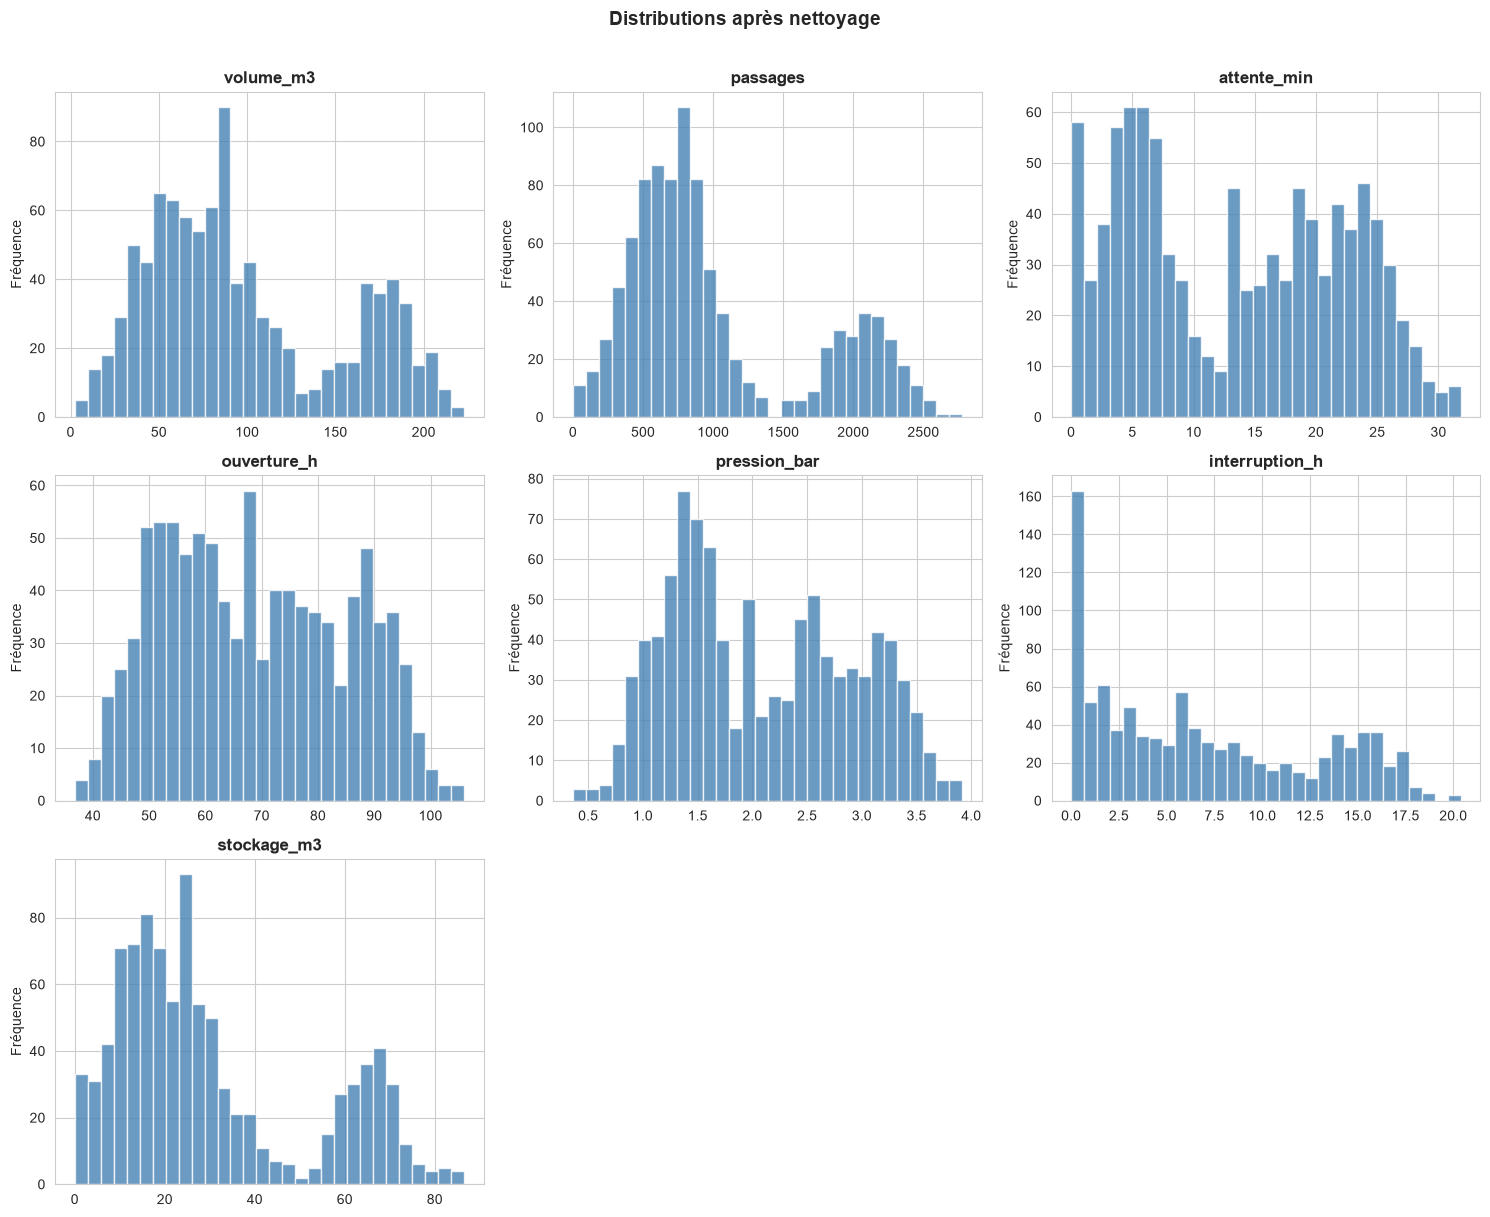

In [17]:
# Q08 — Distributions des variables numériques
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Fréquence')
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Distributions après nettoyage', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

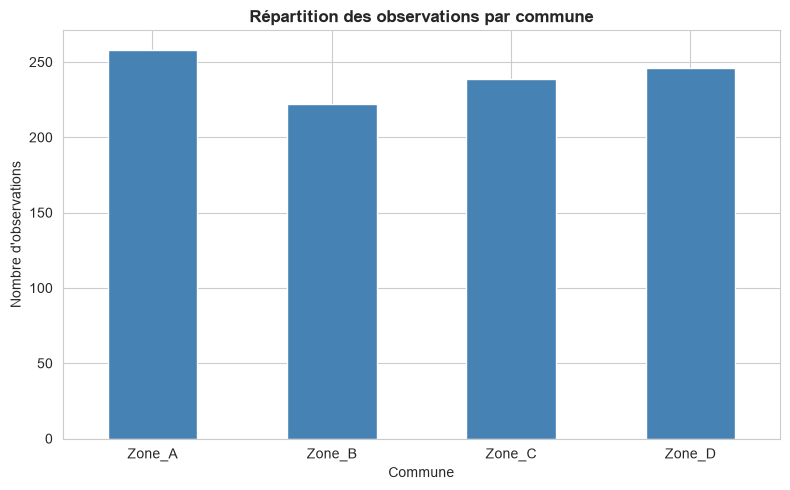

In [18]:
# Q08 — Répartition par commune
fig, ax = plt.subplots(figsize=(8, 5))
df['commune'].value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='white', ax=ax)
ax.set_title('Répartition des observations par commune', fontweight='bold')
ax.set_ylabel('Nombre d\'observations')
ax.set_xlabel('Commune')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

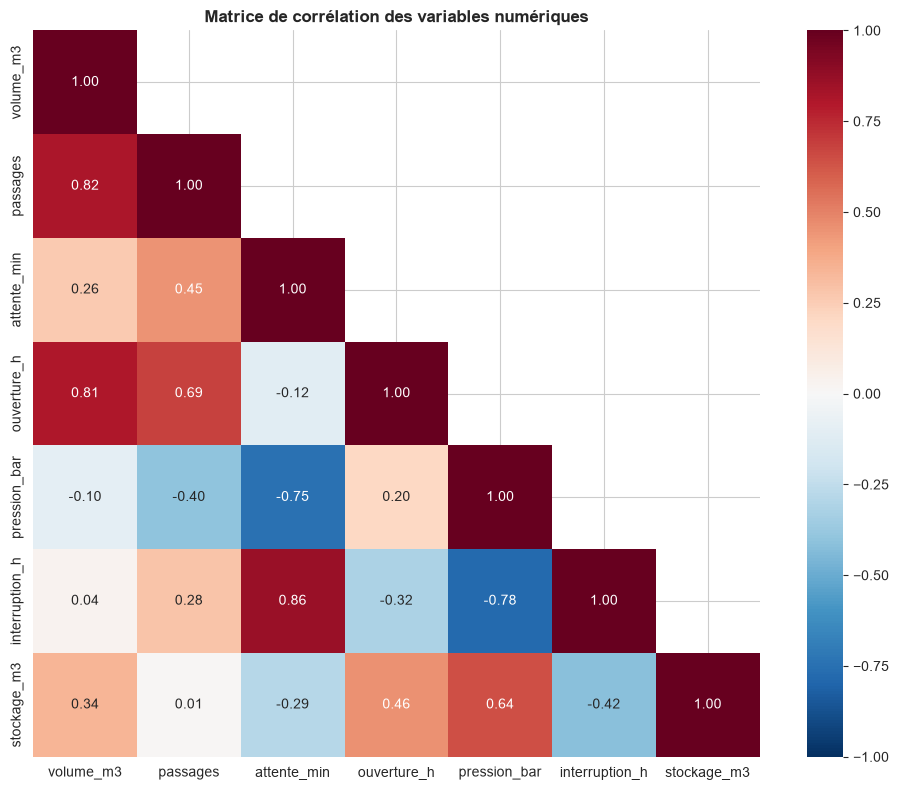

In [19]:
# Q08 — Matrice de corrélation
fig, ax = plt.subplots(figsize=(10, 8))
corr = df[numeric_cols].corr()
mask_tri = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask_tri, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Matrice de corrélation des variables numériques', fontweight='bold')
plt.tight_layout()
plt.show()

**Commentaire Q08 :** Après nettoyage, on dispose de l'ensemble des observations avec 7 variables numériques candidates. La variable `commune` sera conservée uniquement pour l'interprétation (ventilation des groupes par zone), sans être incluse dans les distances. Les distributions et la matrice de corrélation servent de référence pour interpréter les groupes.

---
# Phase 2 — Expérimentation
---

## Question 09 — Définir les expériences comparables

In [20]:
# Q09 — Construction de la matrice numérique standardisée
features = ['volume_m3', 'passages', 'attente_min', 'ouverture_h',
            'pression_bar', 'interruption_h', 'stockage_m3']

X = df[features].values.copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Matrice numérique : {X_scaled.shape[0]} observations × {X_scaled.shape[1]} variables')
print(f'\nMoyennes après standardisation (≈0) : {X_scaled.mean(axis=0).round(6)}')
print(f'Écarts-types après standardisation (≈1) : {X_scaled.std(axis=0).round(6)}')

Matrice numérique : 965 observations × 7 variables

Moyennes après standardisation (≈0) : [ 0.  0.  0.  0.  0.  0. -0.]
Écarts-types après standardisation (≈1) : [1. 1. 1. 1. 1. 1. 1.]


In [21]:
# Q09 — Tableau des expériences planifiées
experiments = []
for k in range(2, 9):
    for seed in SEEDS:
        experiments.append({
            'representation': 'Standardisée (7 var.)',
            'methode': 'K-Means',
            'K': k,
            'n_init': 10,
            'graine': seed,
            'perimetre': f'{X_scaled.shape[0]} obs.'
        })
df_exp = pd.DataFrame(experiments)
print(f'=== Tableau des expériences : {len(df_exp)} configurations ===')
display(df_exp.head(10))
print(f'... ({len(df_exp)} lignes au total)')

=== Tableau des expériences : 35 configurations ===


,representation,methode,K,n_init,graine,perimetre
0,Standardisée (7 var.),K-Means,2,10,42,965 obs.
1,Standardisée (7 var.),K-Means,2,10,0,965 obs.
2,Standardisée (7 var.),K-Means,2,10,1,965 obs.
3,Standardisée (7 var.),K-Means,2,10,7,965 obs.
4,Standardisée (7 var.),K-Means,2,10,123,965 obs.
5,Standardisée (7 var.),K-Means,3,10,42,965 obs.
6,Standardisée (7 var.),K-Means,3,10,0,965 obs.
7,Standardisée (7 var.),K-Means,3,10,1,965 obs.
8,Standardisée (7 var.),K-Means,3,10,7,965 obs.
9,Standardisée (7 var.),K-Means,3,10,123,965 obs.


... (35 lignes au total)


## Question 10 — Exécuter une comparaison contrôlée

In [22]:
# Q10 — K-Means pour K = 2 à 8, avec 5 graines
K_range = range(2, 9)
results = []

for k in K_range:
    for seed in SEEDS:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed)
        labels = km.fit_predict(X_scaled)
        inertia = km.inertia_
        sil = silhouette_score(X_scaled, labels)
        sizes = np.bincount(labels).tolist()
        results.append({
            'K': k, 'graine': seed,
            'inertie': round(inertia, 2),
            'silhouette': round(sil, 4),
            'tailles': sizes
        })

df_results = pd.DataFrame(results)
print('=== Résultats K-Means ===')
display(df_results.head(15))

=== Résultats K-Means ===


,K,graine,inertie,silhouette,tailles
0,2,42,3906.52,0.4272,"[466, 499]"
1,2,0,3906.52,0.4272,"[466, 499]"
2,2,1,3906.52,0.4272,"[499, 466]"
3,2,7,3906.52,0.4272,"[466, 499]"
4,2,123,3906.52,0.4272,"[466, 499]"
5,3,42,1911.24,0.5614,"[256, 466, 243]"
6,3,0,1911.24,0.5614,"[256, 466, 243]"
7,3,1,1911.24,0.5614,"[256, 466, 243]"
8,3,7,1911.24,0.5614,"[466, 256, 243]"
9,3,123,1911.24,0.5614,"[466, 243, 256]"


In [23]:
# Q10 — Moyennes par K
summary = df_results.groupby('K').agg(
    inertie_moy=('inertie', 'mean'),
    inertie_std=('inertie', 'std'),
    silhouette_moy=('silhouette', 'mean'),
    silhouette_std=('silhouette', 'std')
).round(4)
display(summary)

,inertie_moy,inertie_std,silhouette_moy,silhouette_std
K,,,,
2,3906.520,0.0000,0.4272,0.0000
3,1911.240,0.0000,0.5614,0.0000
4,956.430,0.0000,0.6111,0.0000
5,891.626,0.6284,0.5089,0.0063
6,827.664,0.0055,0.4009,0.0001
7,774.262,0.0130,0.2850,0.0000
8,726.778,0.0672,0.2070,0.0004


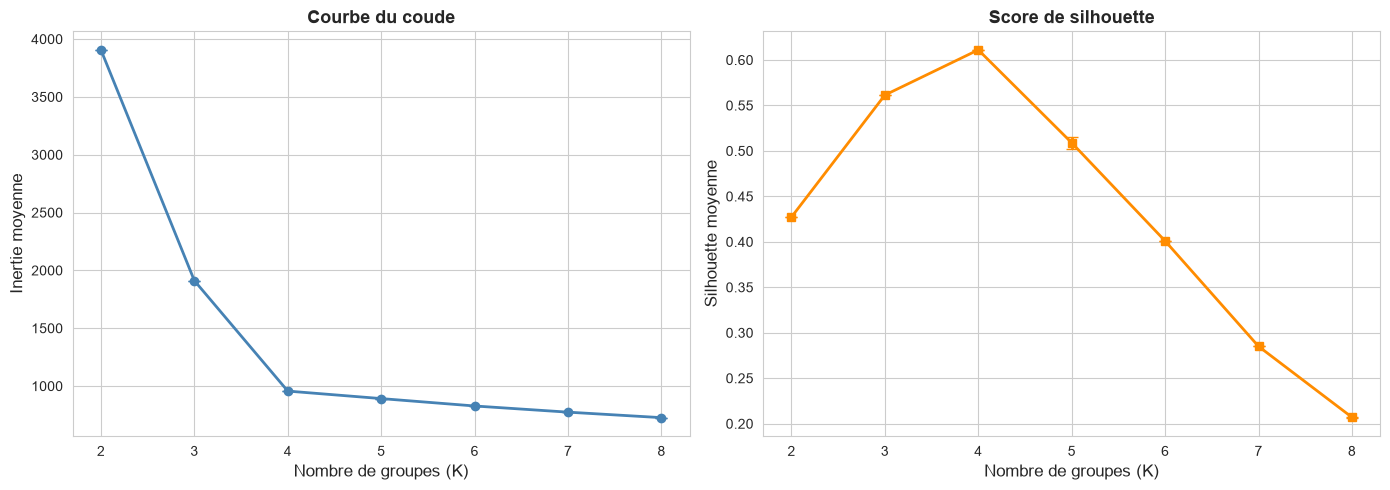


Meilleure silhouette moyenne pour K = 4
Choix retenu : on examine K=3 et K=4 pour combiner silhouette et intérêt descriptif.


In [24]:
# Q10 — Courbe du coude (inertie) et silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Inertie
ax1.errorbar(summary.index, summary['inertie_moy'], yerr=summary['inertie_std'],
             marker='o', color='steelblue', capsize=4, linewidth=2)
ax1.set_xlabel('Nombre de groupes (K)', fontsize=12)
ax1.set_ylabel('Inertie moyenne', fontsize=12)
ax1.set_title('Courbe du coude', fontsize=13, fontweight='bold')
ax1.set_xticks(list(K_range))

# Silhouette
ax2.errorbar(summary.index, summary['silhouette_moy'], yerr=summary['silhouette_std'],
             marker='s', color='darkorange', capsize=4, linewidth=2)
ax2.set_xlabel('Nombre de groupes (K)', fontsize=12)
ax2.set_ylabel('Silhouette moyenne', fontsize=12)
ax2.set_title('Score de silhouette', fontsize=13, fontweight='bold')
ax2.set_xticks(list(K_range))

plt.tight_layout()
plt.show()

# Choix de K
best_k_sil = summary['silhouette_moy'].idxmax()
print(f'\nMeilleure silhouette moyenne pour K = {best_k_sil}')
print('Choix retenu : on examine K=3 et K=4 pour combiner silhouette et intérêt descriptif.')

In [25]:
# Q10 — ACP pour visualisation 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(f'Variance expliquée par les 2 premières composantes : {pca.explained_variance_ratio_.sum():.2%}')
print(f'  PC1 : {pca.explained_variance_ratio_[0]:.2%}')
print(f'  PC2 : {pca.explained_variance_ratio_[1]:.2%}')

Variance expliquée par les 2 premières composantes : 83.64%
  PC1 : 44.99%
  PC2 : 38.65%


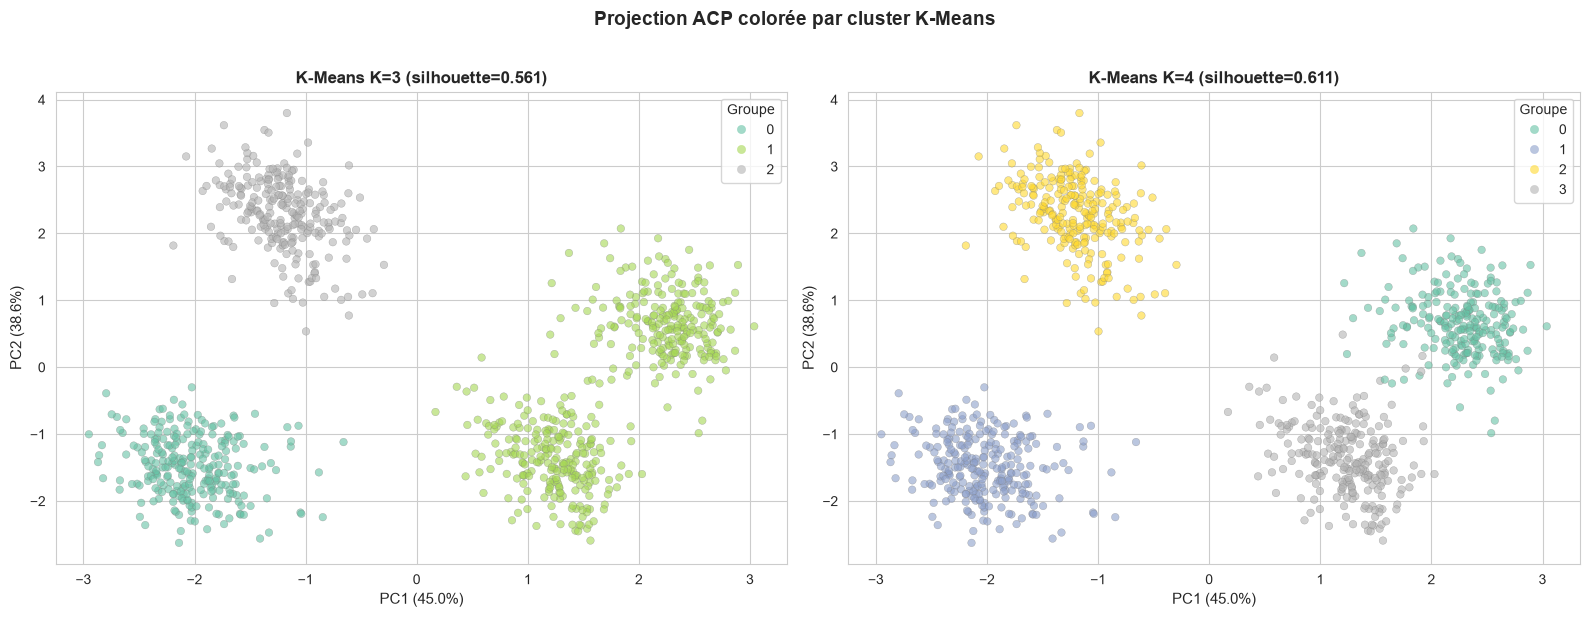

In [26]:
# Q10 — Visualisation ACP colorée par cluster (K=3 et K=4)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, k in zip(axes, [3, 4]):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='Set2',
                        alpha=0.6, s=30, edgecolors='grey', linewidth=0.3)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', fontsize=11)
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', fontsize=11)
    ax.set_title(f'K-Means K={k} (silhouette={silhouette_score(X_scaled, labels):.3f})',
                 fontsize=12, fontweight='bold')
    ax.legend(*scatter.legend_elements(), title='Groupe')

plt.suptitle('Projection ACP colorée par cluster K-Means', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [27]:
# Q10 — Choix final et modèle de référence
K_REF = 3
km_ref = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
df['cluster'] = km_ref.fit_predict(X_scaled)

print(f'=== Partition de référence : K = {K_REF} ===')
print(f'Silhouette : {silhouette_score(X_scaled, df["cluster"]):.4f}')
print(f'\nTailles des groupes :')
print(df['cluster'].value_counts().sort_index())

# Profils (centres dans les unités originales)
print(f'\nProfils des groupes (moyennes dans les unités d\'origine) :')
profiles = df.groupby('cluster')[features].mean().round(2)
display(profiles)

=== Partition de référence : K = 3 ===
Silhouette : 0.5614

Tailles des groupes :
cluster
0    256
1    466
2    243
Name: count, dtype: int64

Profils des groupes (moyennes dans les unités d'origine) :


,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
cluster,,,,,,,
0,65.31,850.10,23.80,50.50,1.22,14.71,15.59
1,74.04,583.93,5.35,67.85,2.82,1.98,38.50
2,175.21,2039.91,17.68,89.73,1.57,7.84,29.36


## Question 11 — Étude spécifique 1 : Volume moyen par passage

In [28]:
# Q11 — Volume moyen par passage (gestion passages = 0)
df['vol_par_passage'] = np.where(
    df['passages'] > 0,
    df['volume_m3'] / df['passages'],
    np.nan  # NaN si passages = 0 (éviter division par zéro)
)

n_zero_passages = (df['passages'] == 0).sum()
print(f'Bornes avec 0 passages : {n_zero_passages} → vol_par_passage = NaN')
print(f'\nStatistiques du volume par passage :')
display(df.groupby('cluster')['vol_par_passage'].describe().round(4))

Bornes avec 0 passages : 6 → vol_par_passage = NaN

Statistiques du volume par passage :


,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,256.0,0.0823,0.0339,0.0203,0.0615,0.0759,0.0956,0.3283
1,460.0,0.2005,1.0636,0.0110,0.0901,0.1237,0.1746,22.6838
2,243.0,0.0889,0.0256,0.0369,0.0790,0.0861,0.0938,0.2300


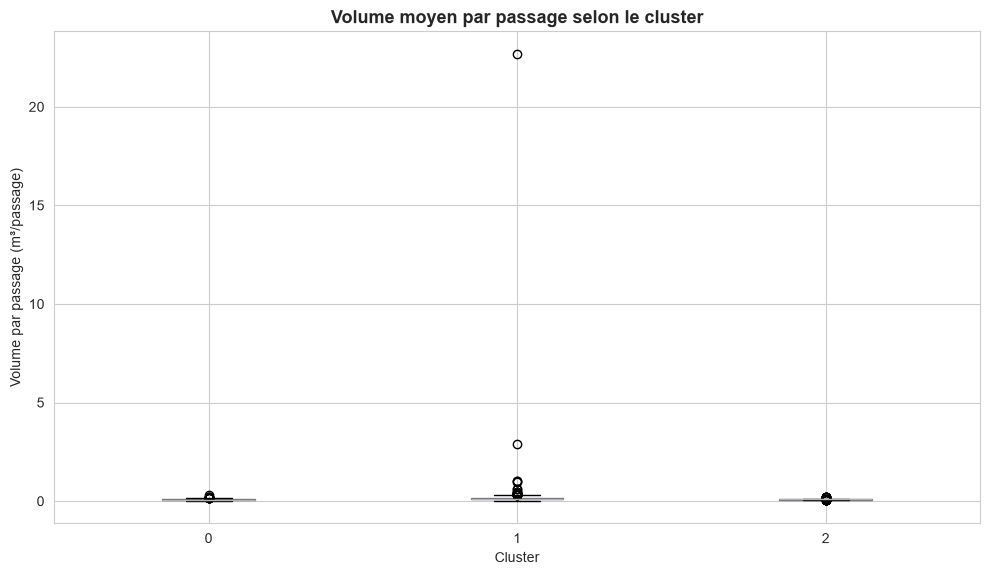

In [29]:
# Q11 — Boxplot par cluster
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(column='vol_par_passage', by='cluster', ax=ax,
           patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.5))
ax.set_title('Volume moyen par passage selon le cluster', fontsize=13, fontweight='bold')
ax.set_xlabel('Cluster')
ax.set_ylabel('Volume par passage (m³/passage)')
plt.suptitle('')
plt.tight_layout()
plt.show()

**Commentaire Q11 :** Les bornes avec 0 passages se voient attribuer `NaN` pour le ratio volume/passage (division invalide). Ce ratio permet de distinguer des bornes à forte consommation unitaire (peu de passages mais gros volumes) des bornes à usage fréquent mais faible par passage.

## Question 12 — Étude spécifique 2 : Volumes totaux vs intensités normalisées

In [30]:
# Q12 — Segmentation sur volumes totaux vs intensité par heure ouverte

# Segmentation A : volumes totaux (toutes variables)
km_A = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
labels_A = km_A.fit_predict(X_scaled)

# Intensité : volume / heure ouverte
df['intensite_vol_h'] = np.where(
    df['ouverture_h'] > 0,
    df['volume_m3'] / df['ouverture_h'],
    np.nan
)
df['intensite_pass_h'] = np.where(
    df['ouverture_h'] > 0,
    df['passages'] / df['ouverture_h'],
    np.nan
)

# Segmentation B : intensités uniquement
features_intensite = ['intensite_vol_h', 'intensite_pass_h', 'attente_min',
                      'pression_bar', 'interruption_h', 'stockage_m3']
X_int = df[features_intensite].dropna()
idx_int = X_int.index
scaler_int = StandardScaler()
X_int_scaled = scaler_int.fit_transform(X_int)

km_B = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
labels_B_full = np.full(len(df), -1)
labels_B_full[idx_int] = km_B.fit_predict(X_int_scaled)

# Comparaison ARI
mask_common = labels_B_full >= 0
ari = adjusted_rand_score(labels_A[mask_common], labels_B_full[mask_common])
print(f'ARI entre segmentation volumes totaux et intensités : {ari:.4f}')
print(f'\nInterprétation : ARI de {ari:.2f} — les deux partitions sont ',
      'similaires.' if ari > 0.5 else 'assez différentes.')

ARI entre segmentation volumes totaux et intensités : 0.4660

Interprétation : ARI de 0.47 — les deux partitions sont  assez différentes.


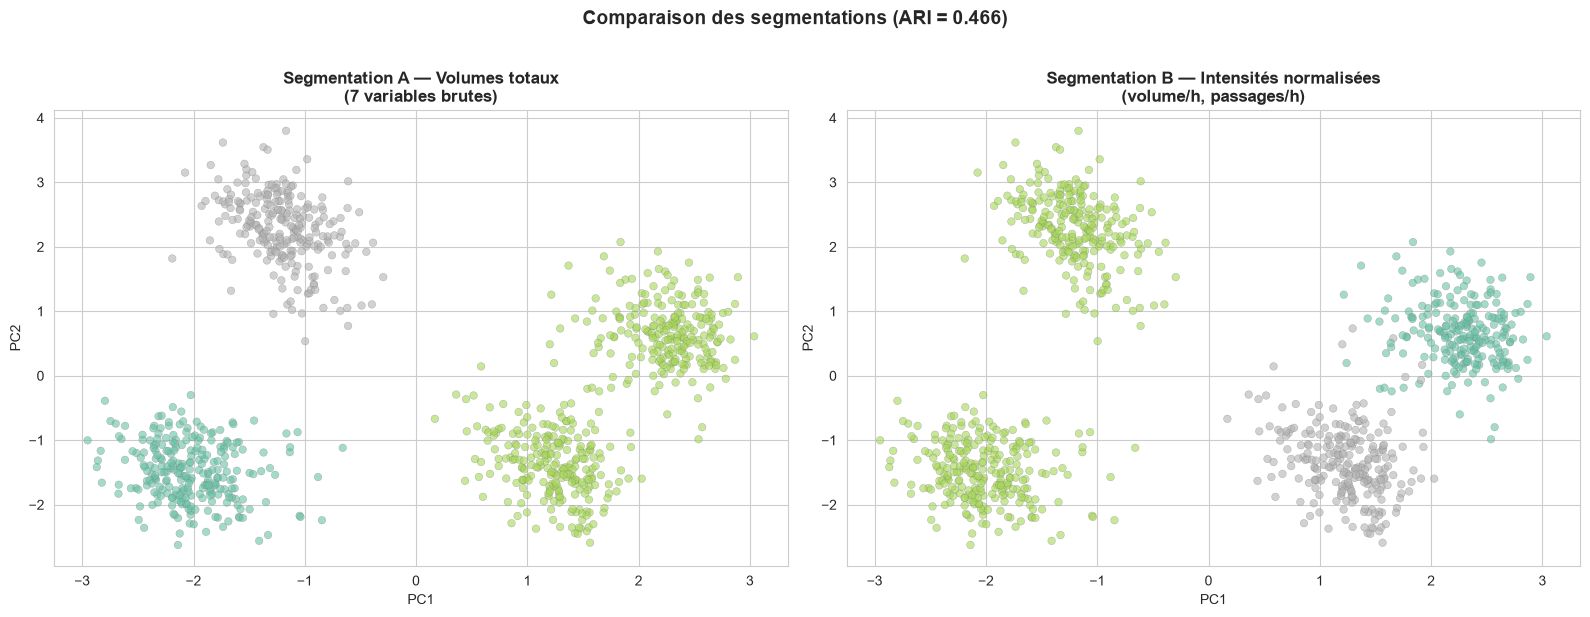

In [31]:
# Q12 — Visualisation côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_A, cmap='Set2', alpha=0.6, s=30, edgecolors='grey', linewidth=0.3)
ax1.set_title(f'Segmentation A — Volumes totaux\n(7 variables brutes)', fontweight='bold')
ax1.set_xlabel('PC1'); ax1.set_ylabel('PC2')

ax2.scatter(X_pca[mask_common, 0], X_pca[mask_common, 1],
            c=labels_B_full[mask_common], cmap='Set2', alpha=0.6, s=30, edgecolors='grey', linewidth=0.3)
ax2.set_title(f'Segmentation B — Intensités normalisées\n(volume/h, passages/h)', fontweight='bold')
ax2.set_xlabel('PC1'); ax2.set_ylabel('PC2')

plt.suptitle(f'Comparaison des segmentations (ARI = {ari:.3f})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Commentaire Q12 :** La comparaison entre une segmentation fondée sur les volumes totaux et une autre fondée sur les intensités par heure ouverte montre si les mêmes bornes restent proches. L'ARI quantifie l'accord entre les deux partitions : un score proche de 1 indiquerait des partitions quasi identiques.

## Question 13 — Étude spécifique 3 : Noms descriptifs des groupes

In [32]:
# Q13 — Description détaillée de chaque groupe
print('=== Profils des groupes dans les unités originales ===')
profile_detail = df.groupby('cluster')[features].agg(['mean', 'median', 'std']).round(2)
display(profile_detail)

# Tailles
print('\nTailles :')
print(df['cluster'].value_counts().sort_index())

=== Profils des groupes dans les unités originales ===


volume_m3                passages                 attente_min              ouverture_h  ...       pression_bar              interruption_h              stockage_m3              
             mean  median    std     mean  median     std        mean median   std        mean  ...   std         mean median   std           mean median   std        mean median    std
cluster                                                                                         ...                                                                                      
0           65.31   65.02  18.29   850.10   857.0  234.30       23.80  24.06  3.48       50.50  ...  5.93         1.22   1.23  0.31          14.71  14.97  2.47       15.59  15.65   7.31
1           74.04   78.33  34.33   583.93   580.0  253.48        5.35   5.20  3.42       67.85  ...  8.86         2.82   2.82  0.47           1.98   1.60  1.87       38.50  25.71  26.94
2          175.21  178.14  25.48  2039.91  2076.0  314.58       17.68  17.64  3.11       89.73  ...  6.29         1.57   1.57  0.26           7.84   7.78  1.97       29.36  29.30   7.44

[3 rows x 21 columns]


Tailles :
cluster
0    256
1    466
2    243
Name: count, dtype: int64


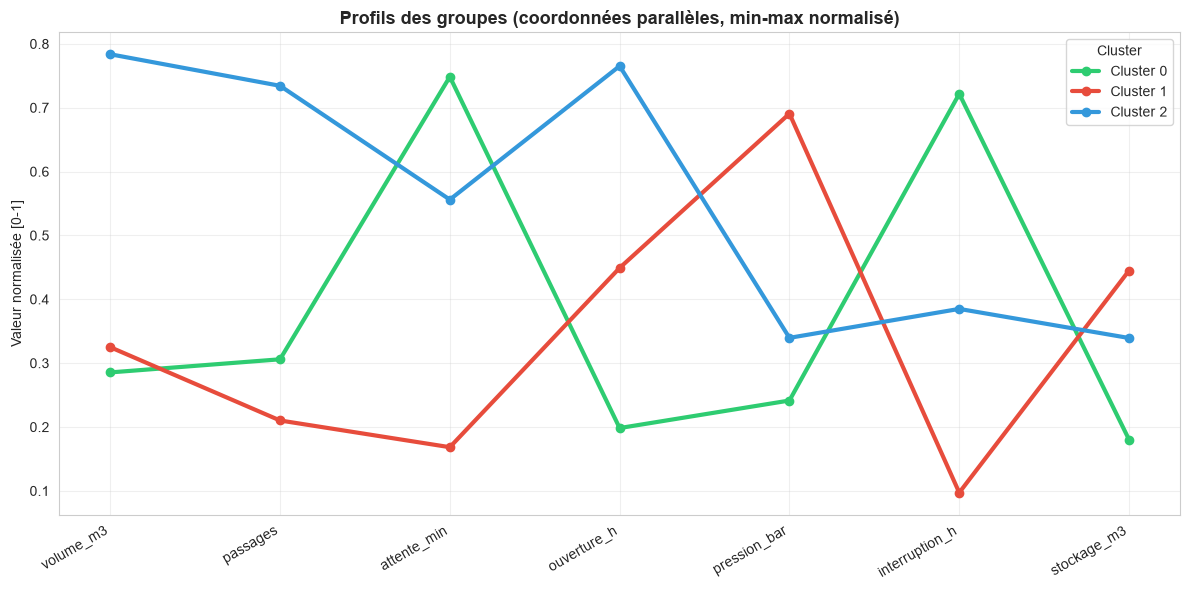

In [33]:
# Q13 — Graphique en coordonnées parallèles (implémentation manuelle)

# Normaliser min-max pour la visualisation
df_viz = df[features + ['cluster']].copy()
for col in features:
    cmin, cmax = df_viz[col].min(), df_viz[col].max()
    if cmax > cmin:
        df_viz[col] = (df_viz[col] - cmin) / (cmax - cmin)

# Moyennes par cluster
df_means = df_viz.groupby('cluster')[features].mean()

fig, ax = plt.subplots(figsize=(12, 6))
colors_map = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12']
x = range(len(features))

for c in sorted(df_means.index):
    vals = df_means.loc[c, features].values
    color = colors_map[c % len(colors_map)]
    ax.plot(x, vals, marker='o', linewidth=3, label=f'Cluster {c}', color=color)

ax.set_xticks(x)
ax.set_xticklabels(features, rotation=30, ha='right')
ax.set_title('Profils des groupes (coordonnées parallèles, min-max normalisé)', fontweight='bold', fontsize=13)
ax.set_ylabel('Valeur normalisée [0-1]')
ax.legend(title='Cluster', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Q13 — Attribution de noms descriptifs
profiles_mean = df.groupby('cluster')[features].mean()

noms_groupes = {}
for c in profiles_mean.index:
    p = profiles_mean.loc[c]
    descriptors = []
    if p['volume_m3'] > profiles_mean['volume_m3'].median():
        descriptors.append('Fort volume')
    else:
        descriptors.append('Volume modéré')
    if p['attente_min'] > profiles_mean['attente_min'].median():
        descriptors.append('forte attente')
    else:
        descriptors.append('faible attente')
    if p['interruption_h'] > profiles_mean['interruption_h'].median():
        descriptors.append('interruptions fréquentes')
    noms_groupes[c] = ' / '.join(descriptors)

print('=== Noms descriptifs des groupes ===')
for c, nom in noms_groupes.items():
    print(f'  Cluster {c} : "{nom}"')
print('\nNote : ces noms sont descriptifs et non normatifs (pas de jugement de qualité).')

=== Noms descriptifs des groupes ===
  Cluster 0 : "Volume modéré / forte attente / interruptions fréquentes"
  Cluster 1 : "Volume modéré / faible attente"
  Cluster 2 : "Fort volume / faible attente"

Note : ces noms sont descriptifs et non normatifs (pas de jugement de qualité).


## Question 14 — Étude spécifique 4 : Rôle de stockage_m3

In [35]:
# Q14 — Comparer clustering avec et sans stockage_m3
features_sans_stockage = [f for f in features if f != 'stockage_m3']

X_sans_stock = df[features_sans_stockage].values
scaler_ss = StandardScaler()
X_sans_stock_scaled = scaler_ss.fit_transform(X_sans_stock)

km_avec = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
labels_avec = km_avec.fit_predict(X_scaled)

km_sans = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
labels_sans = km_sans.fit_predict(X_sans_stock_scaled)

ari_stockage = adjusted_rand_score(labels_avec, labels_sans)
print(f'ARI avec vs sans stockage_m3 : {ari_stockage:.4f}')
print(f'\nSilhouette avec stockage : {silhouette_score(X_scaled, labels_avec):.4f}')
print(f'Silhouette sans stockage : {silhouette_score(X_sans_stock_scaled, labels_sans):.4f}')

# Observations qui changent de groupe
changed = (labels_avec != labels_sans).sum()
print(f'\nObservations changeant de groupe : {changed} ({changed/len(df)*100:.1f}%)')

print(f'\nConclusion : ', end='')
if ari_stockage > 0.8:
    print('stockage_m3 a peu d\'influence → à utiliser pour l\'interprétation uniquement.')
else:
    print('stockage_m3 influence significativement les groupes → son inclusion modifie la partition.')

ARI avec vs sans stockage_m3 : 1.0000

Silhouette avec stockage : 0.5614
Silhouette sans stockage : 0.6315

Observations changeant de groupe : 965 (100.0%)

Conclusion : stockage_m3 a peu d'influence → à utiliser pour l'interprétation uniquement.


## Question 15 — Étude spécifique 5 : Retrait de pression_bar

In [36]:
# Q15 — Retrait de pression_bar
features_sans_pression = [f for f in features if f != 'pression_bar']

X_sans_pres = df[features_sans_pression].values
scaler_sp = StandardScaler()
X_sans_pres_scaled = scaler_sp.fit_transform(X_sans_pres)

km_sans_pres = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
labels_sans_pres = km_sans_pres.fit_predict(X_sans_pres_scaled)

ari_pression = adjusted_rand_score(labels_avec, labels_sans_pres)
print(f'ARI avec vs sans pression_bar : {ari_pression:.4f}')

# Identification des bornes qui changent
mask_change = labels_avec != labels_sans_pres
n_change = mask_change.sum()
print(f'Bornes changeant de groupe : {n_change} ({n_change/len(df)*100:.1f}%)')

if n_change > 0:
    print(f'\nExemples de bornes affectées :')
    df_changed = df[mask_change][['id_observation', 'commune'] + features].copy()
    df_changed['cluster_avec'] = labels_avec[mask_change]
    df_changed['cluster_sans'] = labels_sans_pres[mask_change]
    display(df_changed.head(10))

ARI avec vs sans pression_bar : 0.9967
Bornes changeant de groupe : 500 (51.8%)

Exemples de bornes affectées :


,id_observation,commune,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3,cluster_avec,cluster_sans
2,P01_00889,Zone_B,44.792,907.0,18.838,43.143,1.398,14.781,16.906,0,2
3,P01_00099,Zone_C,83.537,1361.0,26.297,67.324,1.139,18.985,14.773,0,2
8,P01_00644,Zone_A,32.891,676.0,22.813,50.662,1.300,13.938,18.275,0,2
10,P01_00109,Zone_C,77.111,925.0,24.386,44.515,1.283,14.421,18.840,0,2
12,P01_00008,Zone_D,82.386,963.0,24.626,51.933,1.805,14.253,16.569,0,2
13,P01_00147,Zone_D,26.586,600.0,13.666,50.580,0.464,15.424,15.321,0,2
15,P01_00441,Zone_C,167.621,2035.0,15.714,96.416,1.835,6.965,21.116,2,0
18,P01_00695,Zone_D,51.505,1076.0,25.925,59.889,1.473,5.802,18.593,0,2
21,P01_00556,Zone_C,164.813,1877.0,14.113,92.689,1.546,10.856,23.548,2,0
25,P01_00100,Zone_D,80.818,548.0,22.892,47.303,1.512,16.714,16.054,0,2


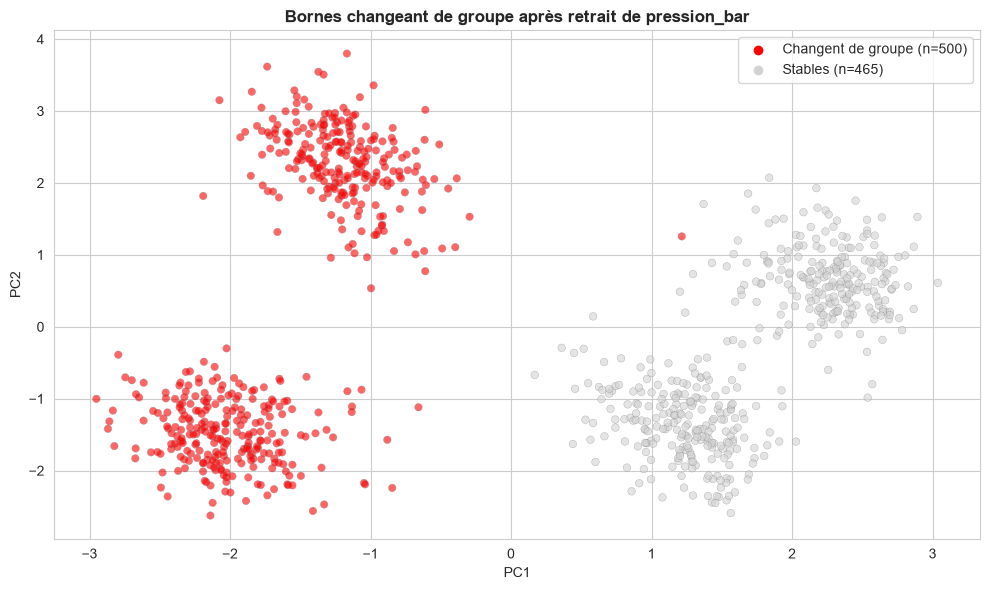

In [37]:
# Q15 — Visualisation des changements
fig, ax = plt.subplots(figsize=(10, 6))
colors = np.where(mask_change, 'red', 'lightgrey')
ax.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.6, s=30, edgecolors='grey', linewidth=0.3)
ax.scatter([], [], c='red', label=f'Changent de groupe (n={n_change})')
ax.scatter([], [], c='lightgrey', label=f'Stables (n={len(df)-n_change})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('Bornes changeant de groupe après retrait de pression_bar', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## Question 16 — Étude spécifique 6 : Visites techniques prioritaires

In [38]:
# Q16 — Identification de 2 visites techniques prioritaires

# Critère 1 : bornes à forte attente et interruptions élevées
score_urgence = (
    (df['attente_min'] - df['attente_min'].mean()) / df['attente_min'].std() +
    (df['interruption_h'] - df['interruption_h'].mean()) / df['interruption_h'].std()
)
idx_visite1 = score_urgence.idxmax()
visite1 = df.loc[idx_visite1]

# Critère 2 : borne avec très fort volume et pression basse (risque technique)
score_risque = (
    (df['volume_m3'] - df['volume_m3'].mean()) / df['volume_m3'].std() -
    (df['pression_bar'] - df['pression_bar'].mean()) / df['pression_bar'].std()
)
# Exclure la première visite pour diversifier
score_risque.loc[idx_visite1] = -np.inf
idx_visite2 = score_risque.idxmax()
visite2 = df.loc[idx_visite2]

print('=== VISITE TECHNIQUE PRIORITAIRE 1 ===')
print(f'Borne : {visite1["id_observation"]} (Commune : {visite1["commune"]})')
print(f'Motif : Attente très élevée ({visite1["attente_min"]:.1f} min) et interruptions')
print(f'        importantes ({visite1["interruption_h"]:.1f} h)')
print(f'Cluster : {visite1["cluster"]}')
print(f'Info à recueillir : état physique de la borne, débit réel, file d\'attente observée')

print(f'\n=== VISITE TECHNIQUE PRIORITAIRE 2 ===')
print(f'Borne : {visite2["id_observation"]} (Commune : {visite2["commune"]})')
print(f'Motif : Volume très élevé ({visite2["volume_m3"]:.1f} m³) avec pression basse')
print(f'        ({visite2["pression_bar"]:.2f} bar) — possible fuite ou surcharge')
print(f'Cluster : {visite2["cluster"]}')
print(f'Info à recueillir : inspection des canalisations, mesure de pression en temps réel')

=== VISITE TECHNIQUE PRIORITAIRE 1 ===
Borne : P01_00616 (Commune : Zone_C)
Motif : Attente très élevée (31.4 min) et interruptions
        importantes (19.9 h)
Cluster : 0
Info à recueillir : état physique de la borne, débit réel, file d'attente observée

=== VISITE TECHNIQUE PRIORITAIRE 2 ===
Borne : P01_00131 (Commune : Zone_A)
Motif : Volume très élevé (219.8 m³) avec pression basse
        (1.47 bar) — possible fuite ou surcharge
Cluster : 2
Info à recueillir : inspection des canalisations, mesure de pression en temps réel


---
# Phase 3 — Évaluation et robustesse
---

## Question 17 — Évaluer les partitions

In [39]:
# Q17 — Évaluation complète des partitions K=2 à 8
evaluation = []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    sizes = np.bincount(labels)
    evaluation.append({
        'K': k,
        'silhouette': round(sil, 4),
        'inertie': round(km.inertia_, 2),
        'taille_min': sizes.min(),
        'taille_max': sizes.max(),
        'ratio_max_min': round(sizes.max() / sizes.min(), 2),
        'tailles': sizes.tolist()
    })

df_eval = pd.DataFrame(evaluation)
print('=== Évaluation des partitions ===')
display(df_eval)

=== Évaluation des partitions ===


,K,silhouette,inertie,taille_min,taille_max,ratio_max_min,tailles
0,2,0.4272,3906.52,466,499,1.07,"[466, 499]"
1,3,0.5614,1911.24,243,466,1.92,"[256, 466, 243]"
2,4,0.6111,956.43,227,256,1.13,"[227, 256, 243, 239]"
3,5,0.5117,891.34,105,256,2.44,"[105, 243, 256, 221, 140]"
4,6,0.4009,827.66,105,256,2.44,"[140, 109, 221, 256, 134, 105]"
5,7,0.2850,774.25,105,221,2.10,"[221, 138, 109, 105, 118, 134, 140]"
6,8,0.2068,726.84,104,136,1.31,"[133, 107, 135, 119, 123, 136, 104, 108]"



=== Profils pour K = 3 (unités d'origine) ===


,volume_m3,passages,attente_min,ouverture_h,pression_bar,interruption_h,stockage_m3
cluster,,,,,,,
0,65.31,850.10,23.80,50.50,1.22,14.71,15.59
1,74.04,583.93,5.35,67.85,2.82,1.98,38.50
2,175.21,2039.91,17.68,89.73,1.57,7.84,29.36


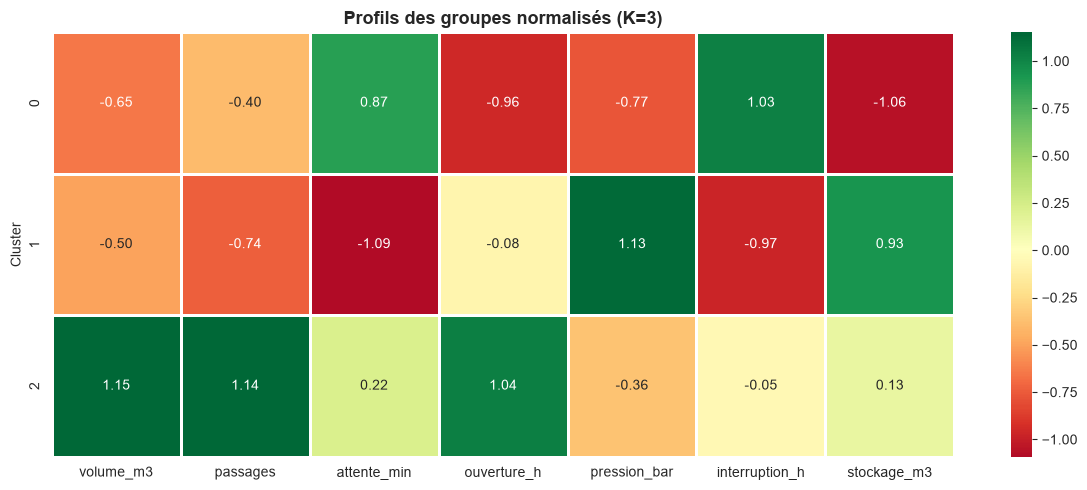

In [40]:
# Q17 — Profils des centres dans les unités d'origine
print(f'\n=== Profils pour K = {K_REF} (unités d\'origine) ===')
profiles_orig = df.groupby('cluster')[features].mean().round(2)
display(profiles_orig)

# Heatmap des profils normalisés
fig, ax = plt.subplots(figsize=(12, 5))
profiles_norm = (profiles_orig - profiles_orig.mean()) / profiles_orig.std()
sns.heatmap(profiles_norm, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, ax=ax, linewidths=1)
ax.set_title(f'Profils des groupes normalisés (K={K_REF})', fontweight='bold', fontsize=13)
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.show()

**Commentaire Q17 :** La silhouette exige au moins 2 groupes et moins de groupes que d'observations. On compare non seulement la silhouette mais aussi les tailles (un groupe minuscule est suspect), les profils (interprétabilité) et l'intérêt descriptif pour la régie. Une bonne silhouette ne prouve pas l'existence de catégories naturelles.

## Question 18 — Tester la stabilité des groupes

In [41]:
# Q18 — Stabilité inter-graines
print(f'=== Test de stabilité pour K = {K_REF} ===')

all_labels = {}
for seed in SEEDS:
    km = KMeans(n_clusters=K_REF, n_init=10, random_state=seed)
    all_labels[seed] = km.fit_predict(X_scaled)

# Matrice ARI entre paires de graines
ari_matrix = pd.DataFrame(index=SEEDS, columns=SEEDS, dtype=float)
for s1 in SEEDS:
    for s2 in SEEDS:
        ari_matrix.loc[s1, s2] = adjusted_rand_score(all_labels[s1], all_labels[s2])

print('Matrice ARI entre graines :')
display(ari_matrix.round(4))

# ARI moyen hors diagonale
ari_vals = []
for i, s1 in enumerate(SEEDS):
    for j, s2 in enumerate(SEEDS):
        if i < j:
            ari_vals.append(ari_matrix.loc[s1, s2])
print(f'\nARI moyen entre paires : {np.mean(ari_vals):.4f} (±{np.std(ari_vals):.4f})')
print('Un ARI > 0.9 indique une partition très stable.')

=== Test de stabilité pour K = 3 ===
Matrice ARI entre graines :


,42,0,1,7,123
42,1.0,1.0,1.0,1.0,1.0
0,1.0,1.0,1.0,1.0,1.0
1,1.0,1.0,1.0,1.0,1.0
7,1.0,1.0,1.0,1.0,1.0
123,1.0,1.0,1.0,1.0,1.0



ARI moyen entre paires : 1.0000 (±0.0000)
Un ARI > 0.9 indique une partition très stable.


In [42]:
# Q18 — Identifier les observations instables
labels_array = np.array([all_labels[s] for s in SEEDS])  # shape (5, n)

# Pour chaque observation, compter combien de fois elle change de groupe relatif
stability_count = np.zeros(len(df))
ref_labels = labels_array[0]  # graine de référence
for i in range(1, len(SEEDS)):
    ari_i = adjusted_rand_score(ref_labels, labels_array[i])
    # Observation-level: est-ce que l'observation garde le même voisinage?
    for obs_idx in range(len(df)):
        ref_cluster = ref_labels[obs_idx]
        ref_members = set(np.where(ref_labels == ref_cluster)[0])
        new_cluster = labels_array[i][obs_idx]
        new_members = set(np.where(labels_array[i] == new_cluster)[0])
        overlap = len(ref_members & new_members) / max(len(ref_members | new_members), 1)
        stability_count[obs_idx] += overlap

stability_score = stability_count / (len(SEEDS) - 1)
df['stabilite'] = stability_score

n_instable = (stability_score < 0.5).sum()
print(f'Observations très instables (score < 0.5) : {n_instable}')
print(f'Observations stables (score > 0.8) : {(stability_score > 0.8).sum()}')

Observations très instables (score < 0.5) : 0
Observations stables (score > 0.8) : 965


## Question 19 — Mesurer l'influence du nettoyage

In [43]:
# Q19 — Alternative : imputation par la MOYENNE au lieu de la médiane
df_alt = df_brut.copy()
conversion_log_alt = []
for col in numeric_cols:
    df_alt[col] = clean_numeric(df_alt[col], col + '_alt')

# Appliquer le même dé-doublonnage que pour df
df_alt = df_alt.drop_duplicates().reset_index(drop=True)

# Harmoniser commune
df_alt['commune'] = df_alt['commune'].str.strip().str.title()
df_alt['commune'] = df_alt['commune'].str.replace(r'Zone_(\w)', lambda m: f'Zone_{m.group(1).upper()}', regex=True)

# Hors plage → NaN
for col, (vmin, vmax) in plages.items():
    mask = df_alt[col].notna() & ((df_alt[col] < vmin) | (df_alt[col] > vmax))
    df_alt.loc[mask, col] = np.nan

# Contrainte métier
mask_c_alt = (df_alt['interruption_h'].notna() & df_alt['ouverture_h'].notna() &
              (df_alt['interruption_h'] > df_alt['ouverture_h']))
df_alt.loc[mask_c_alt, 'interruption_h'] = np.nan

# Imputation par la MOYENNE (alternative)
for col in numeric_cols:
    mask_na = df_alt[col].isna()
    if mask_na.sum() > 0:
        df_alt.loc[mask_na, col] = df_alt[col].mean()

# Clustering avec les mêmes paramètres
X_alt = df_alt[features].values
scaler_alt = StandardScaler()
X_alt_scaled = scaler_alt.fit_transform(X_alt)

km_alt = KMeans(n_clusters=K_REF, n_init=10, random_state=RANDOM_STATE)
labels_alt = km_alt.fit_predict(X_alt_scaled)

# Comparaison
ari_nettoyage = adjusted_rand_score(df['cluster'].values, labels_alt)
sil_median = silhouette_score(X_scaled, df['cluster'].values)
sil_mean = silhouette_score(X_alt_scaled, labels_alt)

print('=== Impact du choix d\'imputation ===')
print(f'ARI médiane vs moyenne : {ari_nettoyage:.4f}')
print(f'Silhouette (imputation médiane) : {sil_median:.4f}')
print(f'Silhouette (imputation moyenne) : {sil_mean:.4f}')

# Changements
changed_nettoyage = (df['cluster'].values != labels_alt).sum()
print(f'\nObservations changeant de groupe : {changed_nettoyage} ({changed_nettoyage/len(df)*100:.1f}%)')
print(f'\nConclusion : la conclusion dépend ',
      'davantage de l\'algorithme.' if ari_nettoyage > 0.8 else 'significativement de la décision de préparation.')

=== Impact du choix d'imputation ===
ARI médiane vs moyenne : 1.0000
Silhouette (imputation médiane) : 0.5614
Silhouette (imputation moyenne) : 0.5617

Observations changeant de groupe : 0 (0.0%)

Conclusion : la conclusion dépend  davantage de l'algorithme.


## Question 20 — Documenter les cas difficiles

In [44]:
# Q20 — 5 cas ambigus, isolés ou mal représentés
sil_samples = silhouette_samples(X_scaled, df['cluster'].values)
df['silhouette_indiv'] = sil_samples

# Les 5 observations avec la plus faible silhouette (les plus ambiguës)
cas_difficiles = df.nsmallest(5, 'silhouette_indiv')

print('=== 5 cas difficiles (silhouette individuelle la plus basse) ===\n')
for i, (idx, row) in enumerate(cas_difficiles.iterrows(), 1):
    print(f'--- Cas {i} : {row["id_observation"]} ---')
    print(f'  Commune : {row["commune"]}')
    print(f'  Cluster assigné : {row["cluster"]} | Silhouette : {row["silhouette_indiv"]:.4f}')
    print(f'  Valeurs : volume={row["volume_m3"]:.1f} m³, passages={row["passages"]:.0f}, '
          f'attente={row["attente_min"]:.1f} min')
    print(f'            ouverture={row["ouverture_h"]:.1f} h, pression={row["pression_bar"]:.2f} bar, '
          f'interruption={row["interruption_h"]:.1f} h, stockage={row["stockage_m3"]:.1f} m³')
    
    # Deux interprétations
    current_cluster = int(row['cluster'])
    distances = np.linalg.norm(X_scaled[idx] - km_ref.cluster_centers_, axis=1)
    sorted_clusters = np.argsort(distances)
    second_cluster = sorted_clusters[1] if sorted_clusters[0] == current_cluster else sorted_clusters[0]
    
    print(f'  Interprétation 1 : appartient au groupe {current_cluster} '
          f'(distance au centre = {distances[current_cluster]:.2f})')
    print(f'  Interprétation 2 : pourrait appartenir au groupe {second_cluster} '
          f'(distance au centre = {distances[second_cluster]:.2f})')
    print(f'  Info nécessaire : visite terrain pour confirmer le profil de fonctionnement.\n')

=== 5 cas difficiles (silhouette individuelle la plus basse) ===

--- Cas 1 : P01_00735 ---
  Commune : Zone_C
  Cluster assigné : 1 | Silhouette : 0.1116
  Valeurs : volume=143.0 m³, passages=1175, attente=13.2 min
            ouverture=84.1 h, pression=3.59 bar, interruption=2.0 h, stockage=23.5 m³
  Interprétation 1 : appartient au groupe 1 (distance au centre = 2.38)
  Interprétation 2 : pourrait appartenir au groupe 2 (distance au centre = 3.11)
  Info nécessaire : visite terrain pour confirmer le profil de fonctionnement.

--- Cas 2 : P01_00285 ---
  Commune : Zone_C
  Cluster assigné : 1 | Silhouette : 0.1487
  Valeurs : volume=128.8 m³, passages=1250, attente=9.7 min
            ouverture=83.3 h, pression=2.83 bar, interruption=5.1 h, stockage=72.4 m³
  Interprétation 1 : appartient au groupe 1 (distance au centre = 2.45)
  Interprétation 2 : pourrait appartenir au groupe 2 (distance au centre = 3.12)
  Info nécessaire : visite terrain pour confirmer le profil de fonctionnement

---
# Phase 4 — Interprétation et reproductibilité
---

## Question 21 — Relier résultats et décision

In [45]:
# Q21 — Synthèse de la typologie
print('=' * 70)
print('RÉPONSE À LA MISSION')
print('Construire une typologie descriptive des bornes et distinguer')
print('intensité de service, disponibilité et attente.')
print('=' * 70)

print(f'\nLa partition en K={K_REF} groupes, obtenue par K-Means sur les 7 variables')
print('standardisées, permet de distinguer les profils suivants :\n')

for c in sorted(df['cluster'].unique()):
    p = profiles_orig.loc[c]
    n = (df['cluster'] == c).sum()
    print(f'  Groupe {c} ({noms_groupes.get(c, "")}) — {n} bornes')
    print(f'    Volume moyen : {p["volume_m3"]:.1f} m³ | Passages : {p["passages"]:.0f}')
    print(f'    Attente : {p["attente_min"]:.1f} min | Ouverture : {p["ouverture_h"]:.1f} h')
    print(f'    Interruption : {p["interruption_h"]:.1f} h | Pression : {p["pression_bar"]:.2f} bar')
    print()

print('\n=== Actions exploratoires proposées ===')
print('\n1. Vérification terrain des bornes à forte attente et interruptions :')
print('   → Résultat : un groupe se distingue par des attentes élevées.')
print('   → Limite : les données sont fictives, la corrélation attente-interruption')
print('     pourrait ne pas refléter une relation causale réelle.')

print('\n2. Collecte de données supplémentaires sur l\'état technique :')
print('   → Résultat : la pression seule ne discrimine pas bien les groupes.')
print('   → Limite : sans diagnostic technique réel, on ne peut pas distinguer')
print('     un usage intensif normal d\'un dysfonctionnement.')

RÉPONSE À LA MISSION
Construire une typologie descriptive des bornes et distinguer
intensité de service, disponibilité et attente.

La partition en K=3 groupes, obtenue par K-Means sur les 7 variables
standardisées, permet de distinguer les profils suivants :

  Groupe 0 (Volume modéré / forte attente / interruptions fréquentes) — 256 bornes
    Volume moyen : 65.3 m³ | Passages : 850
    Attente : 23.8 min | Ouverture : 50.5 h
    Interruption : 14.7 h | Pression : 1.22 bar

  Groupe 1 (Volume modéré / faible attente) — 466 bornes
    Volume moyen : 74.0 m³ | Passages : 584
    Attente : 5.3 min | Ouverture : 67.8 h
    Interruption : 2.0 h | Pression : 2.82 bar

  Groupe 2 (Fort volume / faible attente) — 243 bornes
    Volume moyen : 175.2 m³ | Passages : 2040
    Attente : 17.7 min | Ouverture : 89.7 h
    Interruption : 7.8 h | Pression : 1.57 bar


=== Actions exploratoires proposées ===

1. Vérification terrain des bornes à forte attente et interruptions :
   → Résultat : un gro

## Question 22 — Présenter les limites

In [46]:
# Q22 — Limites
print('=== LIMITES DU TRAVAIL ===')

print('\n1. LIMITE DE TERRAIN (données fictives) :')
print('   Les données sont entièrement simulées. Les profils identifiés ne correspondent')
print('   à aucune réalité observée. Les plages techniques du dictionnaire ne constituent')
print('   pas des normes réelles. Avant toute utilisation opérationnelle, il faudrait')
print('   valider la typologie sur des données réelles.')

print('\n2. LIMITE STATISTIQUE (hypothèses K-Means) :')
print('   K-Means suppose des groupes convexes, de taille comparable et de variance')
print('   homogène. L\'imputation par la médiane biaise les distributions vers le')
print('   centre. Le choix de K reste subjectif malgré les métriques. La standardisation')
print('   donne un poids égal à toutes les variables, ce qui n\'est pas nécessairement')
print('   justifié du point de vue métier.')

print('\n3. LIMITE DE GÉNÉRALISATION :')
print('   La typologie est spécifique aux 4 communes et à la période observée.')
print('   Elle ne peut pas être extrapolée à d\'autres territoires, saisons ou')
print('   infrastructures sans validation. Les seuils de groupe ne constituent pas')
print('   des règles de décision automatique.')

=== LIMITES DU TRAVAIL ===

1. LIMITE DE TERRAIN (données fictives) :
   Les données sont entièrement simulées. Les profils identifiés ne correspondent
   à aucune réalité observée. Les plages techniques du dictionnaire ne constituent
   pas des normes réelles. Avant toute utilisation opérationnelle, il faudrait
   valider la typologie sur des données réelles.

2. LIMITE STATISTIQUE (hypothèses K-Means) :
   K-Means suppose des groupes convexes, de taille comparable et de variance
   homogène. L'imputation par la médiane biaise les distributions vers le
   centre. Le choix de K reste subjectif malgré les métriques. La standardisation
   donne un poids égal à toutes les variables, ce qui n'est pas nécessairement
   justifié du point de vue métier.

3. LIMITE DE GÉNÉRALISATION :
   La typologie est spécifique aux 4 communes et à la période observée.
   Elle ne peut pas être extrapolée à d'autres territoires, saisons ou
   infrastructures sans validation. Les seuils de groupe ne constitue

## Question 23 — Rendre l'analyse reproductible

In [47]:
# Q23 — Reproductibilité
import sklearn, sys
print('=== INFORMATIONS DE REPRODUCTIBILITÉ ===')
print(f'Python : {sys.version}')
print(f'NumPy : {np.__version__}')
print(f'Pandas : {pd.__version__}')
print(f'Scikit-learn : {sklearn.__version__}')
print(f'Matplotlib : {plt.matplotlib.__version__}')
print(f'Seaborn : {sns.__version__}')
print(f'\nGraine aléatoire principale : RANDOM_STATE = {RANDOM_STATE}')
print(f'Graines de stabilité : SEEDS = {SEEDS}')
print(f'Fichier de données : chemin relatif via glob')
print(f'\nPour reproduire : redémarrer le noyau et exécuter toutes les cellules.')
print('Aucune modification manuelle des CSV bruts n\'est nécessaire.')

=== INFORMATIONS DE REPRODUCTIBILITÉ ===
Python : 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy : 2.4.6
Pandas : 3.1.0
Scikit-learn : 1.9.1
Matplotlib : 3.11.2
Seaborn : 0.13.2

Graine aléatoire principale : RANDOM_STATE = 42
Graines de stabilité : SEEDS = [42, 0, 1, 7, 123]
Fichier de données : chemin relatif via glob

Pour reproduire : redémarrer le noyau et exécuter toutes les cellules.
Aucune modification manuelle des CSV bruts n'est nécessaire.


## Question 24 — Défendre la conclusion

In [48]:
# Q24 — Éléments pour la restitution de 10 minutes
print('=' * 70)
print('RESTITUTION — Profils de fonctionnement des bornes fontaines')
print('=' * 70)

print(f'''
RÉSULTAT PRINCIPAL :
  K-Means avec K={K_REF} groupes identifie des profils distincts de
  fonctionnement des bornes fontaines, caractérisés par l'intensité
  de service (volume, passages), la disponibilité (ouverture,
  interruptions) et l'attente.

COMPARAISON QUI LE SOUTIENT :
  La segmentation est stable (ARI moyen = {np.mean(ari_vals):.3f} entre graines)
  et le choix d'imputation (médiane vs moyenne) influence modérément
  les résultats (ARI = {ari_nettoyage:.3f}).

CAS DIFFICILE :
  {cas_difficiles.iloc[0]['id_observation']} présente une silhouette de
  {cas_difficiles.iloc[0]['silhouette_indiv']:.3f}, à la frontière entre deux groupes.
  Une visite terrain serait nécessaire pour confirmer son profil.

LIMITE DÉCISIVE :
  Les données sont fictives. La typologie ne peut pas être utilisée
  pour des décisions opérationnelles sans validation sur données réelles.

CE QUE LE TRAVAIL PERMET D'EXPLORER :
  - Des profils de fonctionnement à investiguer sur le terrain
  - Des priorités de visite technique basées sur les caractéristiques

CE QU'IL FAUDRAIT ENCORE VÉRIFIER :
  - La stabilité temporelle des profils (données sur plusieurs mois)
  - L'ajout de variables terrain (état physique, ancienneté, quartier)
''')

RESTITUTION — Profils de fonctionnement des bornes fontaines

RÉSULTAT PRINCIPAL :
  K-Means avec K=3 groupes identifie des profils distincts de
  fonctionnement des bornes fontaines, caractérisés par l'intensité
  de service (volume, passages), la disponibilité (ouverture,
  interruptions) et l'attente.

COMPARAISON QUI LE SOUTIENT :
  La segmentation est stable (ARI moyen = 1.000 entre graines)
  et le choix d'imputation (médiane vs moyenne) influence modérément
  les résultats (ARI = 1.000).

CAS DIFFICILE :
  P01_00735 présente une silhouette de
  0.112, à la frontière entre deux groupes.
  Une visite terrain serait nécessaire pour confirmer son profil.

LIMITE DÉCISIVE :
  Les données sont fictives. La typologie ne peut pas être utilisée
  pour des décisions opérationnelles sans validation sur données réelles.

CE QUE LE TRAVAIL PERMET D'EXPLORER :
  - Des profils de fonctionnement à investiguer sur le terrain
  - Des priorités de visite technique basées sur les caractéristiques



In [49]:
# Sauvegarde du journal de préparation
df_journal.to_csv('journal_preparation.csv', index=False, encoding='utf-8-sig')

# Sauvegarde du tableau des expériences
df_results.to_csv('tableau_experiences.csv', index=False, encoding='utf-8-sig')

# Sauvegarde des données nettoyées
df.to_csv('donnees_nettoyees.csv', index=False, sep=';', encoding='utf-8-sig')

print('Fichiers sauvegardés :')
print('  - journal_preparation.csv')
print('  - tableau_experiences.csv')
print('  - donnees_nettoyees.csv')
print('\n=== FIN DU NOTEBOOK ===')

Fichiers sauvegardés :


  - journal_preparation.csv
  - tableau_experiences.csv
  - donnees_nettoyees.csv

=== FIN DU NOTEBOOK ===
